# Zonasi Iklim Kecamatan Indonesia dengan K-Means Clustering

Notebook ini berisi seluruh tahapan analisis: data overview, EDA, preprocessing,
modelling K-Means, evaluasi interpolasi spasial (IDW), dan ekspor hasil ke
`backend/data/weather.db` (SQLite) serta `backend/data/model.json` yang dibaca oleh
backend Bun + Elysia.

In [1]:
import json, sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import BallTree

RAW = Path('../Data hujan.csv')
OUT = Path('../backend/data'); OUT.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (10, 4)

## 1. Data Overview

In [2]:
df_raw = pd.read_csv(RAW, sep=';', decimal=',', encoding='utf-8-sig')
print('Ukuran data :', df_raw.shape)
print('Tanggal     :', df_raw.tanggal.unique(), df_raw.waktu.unique())
print('Provinsi    :', df_raw.provinsi.nunique(), '| Kecamatan:', df_raw.id_kecamatan.nunique())
df_raw.head()

Ukuran data : (6353, 21)
Tanggal     : <StringArray>
['2026-08-29']
Length: 1, dtype: str <StringArray>
['12:00:00']
Length: 1, dtype: str
Provinsi    : 33 | Kecamatan: 6353


,tanggal,waktu,id_kecamatan,provinsi,kecamatan,latitude,longitude,suhu_C,suhu_min_C,suhu_max_C,...,kelembapan_%,tekanan_hPa,cuaca,cuaca_numerik,kategori_cuaca,kategori_cuaca_numerik,kecepatan_angin_m_s,arah_angin_derajat,tutupan_awan_%,visibility_m
0,2026-08-29,12:00:00,3101010,DKI Jakarta,KEPULAUAN SERIBU SELATAN,-5.803887,106.525306,27.31,27.31,27.31,...,70,1010,awan pecah,1,Clouds,1,3.39,30,79,10000.0
1,2026-08-29,12:00:00,3101020,DKI Jakarta,KEPULAUAN SERIBU UTARA,-5.655169,106.567047,27.31,27.31,27.31,...,71,1010,awan pecah,1,Clouds,1,3.55,41,81,10000.0
2,2026-08-29,12:00:00,3171010,DKI Jakarta,JAGAKARSA,-6.330101,106.822237,30.58,29.69,31.01,...,57,1010,awan tersebar,2,Clouds,1,5.14,20,43,10000.0
3,2026-08-29,12:00:00,3171020,DKI Jakarta,PASAR MINGGU,-6.283332,106.844856,30.70,29.84,31.16,...,58,1010,awan tersebar,2,Clouds,1,5.14,20,44,10000.0
4,2026-08-29,12:00:00,3171030,DKI Jakarta,CILANDAK,-6.289798,106.796926,30.64,29.81,31.12,...,58,1010,awan tersebar,2,Clouds,1,5.14,20,45,10000.0


In [3]:
info = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing': df_raw.isna().sum(),
    'unique': df_raw.nunique(),
})
info

,dtype,missing,unique
tanggal,str,0,1
waktu,str,0,1
id_kecamatan,int64,0,6353
provinsi,str,0,33
kecamatan,str,0,6008
latitude,float64,0,6313
longitude,float64,0,6312
suhu_C,float64,0,1561
suhu_min_C,float64,0,1558
suhu_max_C,float64,0,1564


## 2. Exploratory Data Analysis

In [4]:
NUM = ['suhu_C','suhu_min_C','suhu_max_C','rentang_suhu','kelembapan_%','tekanan_hPa',
       'kecepatan_angin_m_s','arah_angin_derajat','tutupan_awan_%','visibility_m']
df_raw[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
suhu_C,6353.0,26.36,3.91,5.57,24.20,26.98,29.25,36.43
suhu_min_C,6353.0,26.31,3.87,5.57,24.20,26.96,29.13,36.43
suhu_max_C,6353.0,26.41,3.94,5.57,24.22,26.99,29.33,36.43
rentang_suhu,6353.0,0.10,0.40,0.00,0.00,0.00,0.00,4.27
kelembapan_%,6353.0,73.07,16.69,32.00,59.00,73.00,89.00,100.00
tekanan_hPa,6353.0,1012.99,2.17,1006.00,1011.00,1013.00,1014.00,1020.00
kecepatan_angin_m_s,6353.0,2.91,2.04,0.00,1.24,2.41,4.23,12.06
arah_angin_derajat,6353.0,145.22,81.46,0.00,88.00,139.00,193.00,360.00
tutupan_awan_%,6353.0,40.40,33.61,0.00,9.00,32.00,69.00,100.00
visibility_m,6330.0,9874.73,895.60,56.00,10000.00,10000.00,10000.00,10000.00


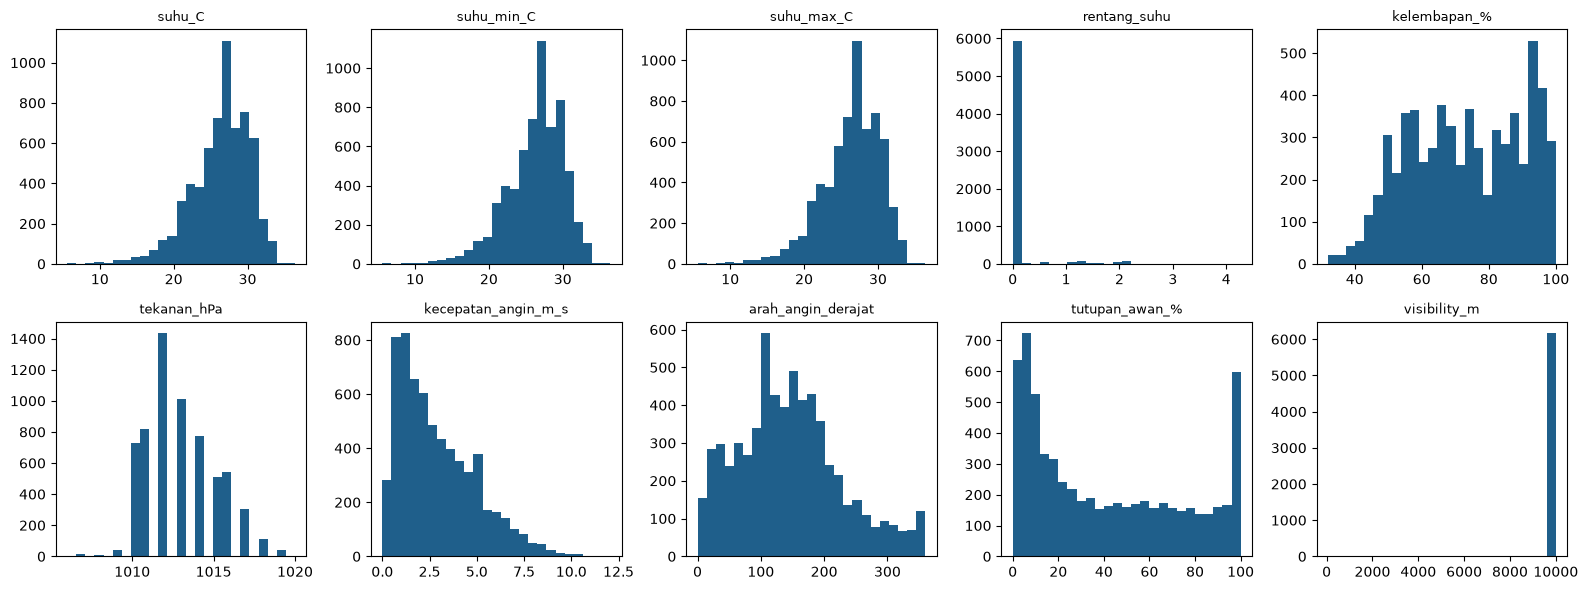

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, c in zip(axes.ravel(), NUM):
    ax.hist(df_raw[c].dropna(), bins=25, color='#1F5F8B')
    ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

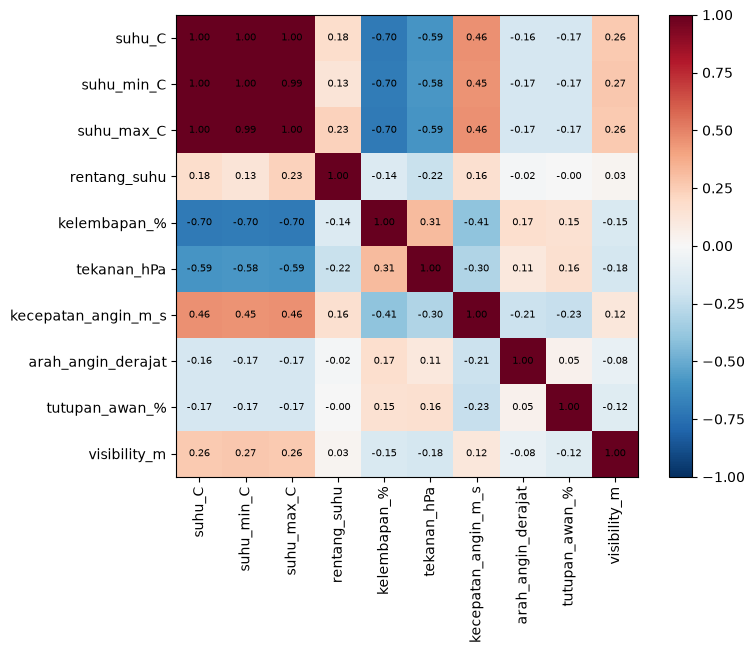

In [6]:
corr = df_raw[NUM].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=90); ax.set_yticks(range(len(NUM)), NUM)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.show()

In [7]:
print(df_raw.kategori_cuaca.value_counts())
print(df_raw.cuaca.value_counts())
df_raw.groupby('provinsi')[['suhu_C','kelembapan_%','kecepatan_angin_m_s']].mean().sort_values('suhu_C').round(2)

kategori_cuaca
Clouds    3966
Clear     1716
Rain       671
Name: count, dtype: int64
cuaca
langit cerah                  1716
awan pecah                    1165
awan tersebar                 1054
sedikit berawan               1012
awan mendung                   735
hujan rintik-rintik            578
hujan sedang                    92
hujan berintensitas tinggi       1
Name: count, dtype: int64


,suhu_C,kelembapan_%,kecepatan_angin_m_s
provinsi,,,
Nusa Tenggara Timur,21.53,82.01,2.75
Kalimantan Tengah,21.73,93.43,0.92
Kalimantan Selatan,22.61,91.47,1.58
Bali,23.10,87.71,3.28
Papua Tengah,23.13,68.38,2.14
Maluku,23.18,85.08,4.10
Kalimantan Utara,23.21,90.92,1.43
Maluku Utara,23.38,85.84,2.94
Nusa Tenggara Barat,23.53,79.39,4.66


**Catatan EDA**
- Data hanya satu waktu pengamatan (29 Agustus 2026, 12:00), jadi 1 baris = 1 kecamatan.
- `suhu_min_C` dan `suhu_max_C` hampir identik dengan `suhu_C` (korelasi mendekati 1) sehingga redundan.
- `rentang_suhu` dan `visibility_m` hampir konstan (mayoritas 0 dan 10.000 m), jadi variasinya sangat kecil.
- Suhu sangat rendah (sekitar 5 °C) muncul di dataran tinggi Papua. Nilainya valid secara fisik, bukan error.
- Provinsi Sulawesi Tengah hanya memiliki 1 kecamatan sehingga hasil untuk provinsi ini kurang representatif.

## 3. Data Preprocessing

In [8]:
df = df_raw.copy()
log = {}

# 3.1 Duplikat
log['duplikat'] = int(df.duplicated('id_kecamatan').sum())
df = df.drop_duplicates('id_kecamatan')

# 3.2 Missing value -> median
log['missing_sebelum'] = {k: int(v) for k, v in df.isna().sum().items() if v > 0}
vis_median = df['visibility_m'].median()
df['visibility_m'] = df['visibility_m'].fillna(vis_median)
log['missing_sesudah'] = int(df.isna().sum().sum())
log['imputasi'] = {'visibility_m': float(vis_median)}

# 3.3 Validasi koordinat: sebagian kecamatan salah geocoding (mis. kecamatan Cirebon jatuh di Sumatera).
#     Titik dianggap anomali jika (a) tidak satu pun dari 10 tetangga terdekatnya berasal dari provinsi
#     yang sama, atau (b) jaraknya ke median lokasi provinsi melebihi Q3 + 3*IQR (dan > 2 derajat).
_c = np.radians(df[['latitude','longitude']].values)
_, _i = BallTree(_c, metric='haversine').query(_c, k=11)
_prov = df.provinsi.to_numpy(dtype=object)
same_share = (_prov[_i[:, 1:]] == _prov[:, None]).mean(1)
_med = df.groupby('provinsi')[['latitude','longitude']].transform('median')
off = np.sqrt(((df[['latitude','longitude']] - _med) ** 2).sum(axis=1)).values
_q = df.assign(off=off).groupby('provinsi')['off'].quantile([.25, .75]).unstack()
lim = df.provinsi.map(_q[0.75] + 3 * (_q[0.75] - _q[0.25])).values
n_prov = df.groupby('provinsi').provinsi.transform('size').values
aturan_provinsi = ((same_share == 0) & (n_prov >= 5)) | ((off > lim) & (off > 2))
# (c) jarak ke median lokasi kabupaten (4 digit pertama id_kecamatan) > max(0,5 derajat, 4 x median jarak di kabupaten itu)
_kab = df.id_kecamatan // 1000
_kmed = df.groupby(_kab)[['latitude','longitude']].transform('median')
_kd = np.sqrt(((df[['latitude','longitude']] - _kmed) ** 2).sum(axis=1))
aturan_kabupaten = (_kd > np.maximum(0.5, 4 * _kd.groupby(_kab).transform('median'))).values
anomali = aturan_provinsi | aturan_kabupaten
log['koordinat_anomali'] = int(anomali.sum())
log['koordinat_anomali_aturan'] = {'provinsi': int(aturan_provinsi.sum()), 'kabupaten': int(aturan_kabupaten.sum())}
log['koordinat_anomali_per_provinsi'] = df[anomali].provinsi.value_counts().to_dict()
log['contoh_anomali'] = df[anomali][['provinsi','kecamatan','latitude','longitude']].head(8).to_dict('records')
df = df[~anomali].reset_index(drop=True)
print('Koordinat anomali dibuang:', anomali.sum())

# 3.4 Outlier (IQR) -> hanya dideteksi, tidak dibuang karena valid secara geografis
FEATURES = ['suhu_C','kelembapan_%','tekanan_hPa','kecepatan_angin_m_s','tutupan_awan_%']
outliers = {}
for c in FEATURES:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    outliers[c] = int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum())
log['outlier_iqr'] = outliers
log

Koordinat anomali dibuang: 620


{'duplikat': 0,
 'missing_sebelum': {'visibility_m': 23},
 'missing_sesudah': 0,
 'imputasi': {'visibility_m': 10000.0},
 'koordinat_anomali': 620,
 'koordinat_anomali_aturan': {'provinsi': 247, 'kabupaten': 550},
 'koordinat_anomali_per_provinsi': {'Jawa Timur': 95,
  'Jawa Tengah': 87,
  'Jawa Barat': 81,
  'Nusa Tenggara Timur': 46,
  'Papua Tengah': 42,
  'Papua Barat': 31,
  'Sulawesi Tenggara': 27,
  'Lampung': 24,
  'Kalimantan Timur': 19,
  'Sulawesi Selatan': 19,
  'Banten': 18,
  'Kalimantan Selatan': 14,
  'Kalimantan Barat': 12,
  'Kalimantan Utara': 11,
  'Bali': 9,
  'Sumatera Utara': 8,
  'Sumatera Barat': 8,
  'Kepulauan Riau': 8,
  'Maluku': 8,
  'Gorontalo': 8,
  'Aceh': 7,
  'Kepulauan Bangka Belitung': 7,
  'Sulawesi Barat': 7,
  'Sumatera Selatan': 5,
  'Nusa Tenggara Barat': 5,
  'Kalimantan Tengah': 5,
  'Bengkulu': 4,
  'Maluku Utara': 4,
  'Jambi': 1},
 'contoh_anomali': [{'provinsi': 'Jawa Barat',
   'kecamatan': 'CIAWI',
   'latitude': -5.928676928,
   'longi

In [9]:
# 3.5 Seleksi fitur
dropped = {
    'suhu_min_C': 'Redundan dengan suhu_C (r > 0.99)',
    'suhu_max_C': 'Redundan dengan suhu_C (r > 0.99)',
    'rentang_suhu': f"Variansi sangat kecil ({(df.rentang_suhu==0).mean():.0%} bernilai 0)",
    'visibility_m': f"Variansi sangat kecil ({(df.visibility_m==10000).mean():.0%} bernilai 10.000 m)",
    'cuaca_numerik': 'Kategorikal (label encoding tidak bermakna jarak)',
    'kategori_cuaca_numerik': 'Kategorikal, dipakai untuk validasi hasil cluster',
    'arah_angin_derajat': 'Variabel sirkular, tidak mencerminkan karakter iklim',
    'latitude / longitude': 'Lokasi tidak dimasukkan agar cluster murni berbasis kondisi cuaca',
}
print('Fitur clustering :', FEATURES)
pd.Series(dropped, name='alasan dibuang')

Fitur clustering : ['suhu_C', 'kelembapan_%', 'tekanan_hPa', 'kecepatan_angin_m_s', 'tutupan_awan_%']


suhu_min_C                                Redundan dengan suhu_C (r > 0.99)
suhu_max_C                                Redundan dengan suhu_C (r > 0.99)
rentang_suhu                         Variansi sangat kecil (93% bernilai 0)
visibility_m                  Variansi sangat kecil (97% bernilai 10.000 m)
cuaca_numerik             Kategorikal (label encoding tidak bermakna jarak)
kategori_cuaca_numerik    Kategorikal, dipakai untuk validasi hasil cluster
arah_angin_derajat        Variabel sirkular, tidak mencerminkan karakter...
latitude / longitude      Lokasi tidak dimasukkan agar cluster murni ber...
Name: alasan dibuang, dtype: str

In [10]:
# 3.6 Standardisasi
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
pd.DataFrame(X, columns=FEATURES).describe().T[['mean','std','min','max']].round(3)

,mean,std,min,max
suhu_C,-0.0,1.0,-5.233,2.103
kelembapan_%,-0.0,1.0,-2.441,1.569
tekanan_hPa,-0.0,1.0,-1.934,3.269
kecepatan_angin_m_s,0.0,1.0,-1.438,4.086
tutupan_awan_%,-0.0,1.0,-1.198,1.778


## 4. Modelling: K-Means Clustering

In [11]:
elbow = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    elbow.append({'k': k, 'inertia': float(km.inertia_),
                  'silhouette': float(silhouette_score(X, km.labels_)),
                  'dbi': float(davies_bouldin_score(X, km.labels_)),
                  'chi': float(calinski_harabasz_score(X, km.labels_))})
elbow_df = pd.DataFrame(elbow); elbow_df.round(3)

,k,inertia,silhouette,dbi,chi
0,2,18299.719,0.316,1.261,3246.139
1,3,15177.442,0.270,1.355,2546.008
2,4,13079.267,0.270,1.197,2275.639
3,5,11179.307,0.268,1.311,2239.813
4,6,9889.458,0.276,1.237,2174.589
5,7,9077.444,0.259,1.192,2059.292
6,8,8430.022,0.265,1.148,1963.141
7,9,7800.218,0.265,1.183,1913.891
8,10,7311.124,0.257,1.191,1857.286


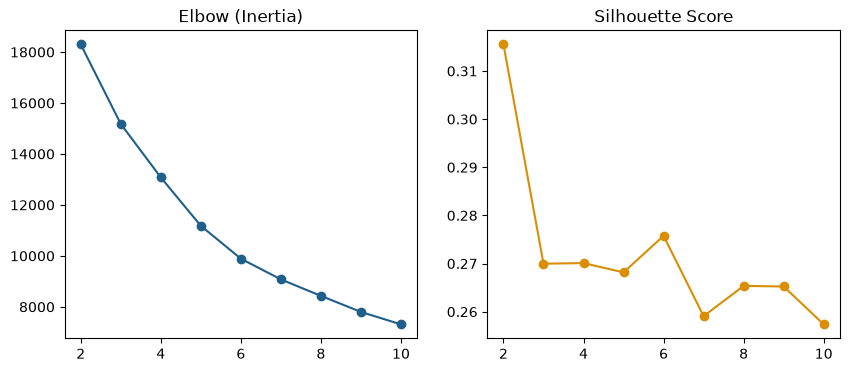

In [12]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(elbow_df.k, elbow_df.inertia, marker='o', color='#1F5F8B'); ax[0].set_title('Elbow (Inertia)')
ax[1].plot(elbow_df.k, elbow_df.silhouette, marker='o', color='#D98E04'); ax[1].set_title('Silhouette Score')
plt.show()

**Pemilihan K = 3.** Penurunan inertia mulai melandai setelah K = 3, dengan silhouette
0,27 (struktur cluster wajar). K = 2 memang punya silhouette tertinggi, tetapi hanya memisahkan
"panas" dan "sejuk" sehingga kurang informatif. K = 3 menghasilkan tiga zona yang jelas
dan mudah ditafsirkan.

In [13]:
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
df['cluster_raw'] = km.labels_
prof = df.groupby('cluster_raw')[FEATURES].mean()

# Penamaan deterministik: cluster terpanas -> 0, sisanya diurutkan dari tutupan awan terendah
hot = prof['suhu_C'].idxmax()
rest = prof.drop(hot).sort_values('tutupan_awan_%').index.tolist()
order = [hot] + rest
remap = {old: new for new, old in enumerate(order)}
df['cluster'] = df['cluster_raw'].map(remap)
centroids_scaled = km.cluster_centers_[order]

CLUSTER_INFO = [
    {'id': 0, 'nama': 'Panas-Kering',
     'deskripsi': 'Suhu tinggi, kelembapan rendah, angin relatif kencang, dan tekanan udara rendah. Umumnya wilayah dataran rendah dan pesisir selatan.'},
    {'id': 1, 'nama': 'Sejuk-Cerah',
     'deskripsi': 'Suhu sedang, kelembapan tinggi, langit cenderung cerah dengan tutupan awan rendah dan angin lemah.'},
    {'id': 2, 'nama': 'Lembap-Berawan',
     'deskripsi': 'Suhu terendah, kelembapan dan tutupan awan paling tinggi. Kelompok ini paling sering mengalami hujan.'},
]
profile = df.groupby('cluster')[FEATURES].mean().round(2)
profile['jumlah'] = df.cluster.value_counts().sort_index()
profile

,suhu_C,kelembapan_%,tekanan_hPa,kecepatan_angin_m_s,tutupan_awan_%,jumlah
cluster,,,,,,
0,29.47,58.60,1012.03,4.21,33.25,2476
1,24.57,83.02,1013.31,1.84,14.72,1704
2,22.93,86.42,1014.53,1.46,79.49,1553


In [14]:
pd.crosstab(df.cluster, df.kategori_cuaca, normalize='index').round(3)

kategori_cuaca,Clear,Clouds,Rain
cluster,,,
0,0.288,0.696,0.016
1,0.498,0.410,0.093
2,0.003,0.709,0.288


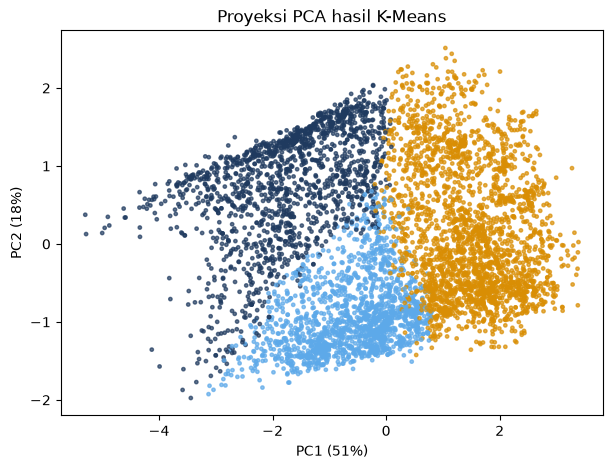

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
colors = np.array(['#D98E04', '#5DA9E9', '#1F3A5F'])
plt.figure(figsize=(7, 5))
plt.scatter(P[:,0], P[:,1], c=colors[df.cluster], s=6, alpha=.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.title('Proyeksi PCA hasil K-Means'); plt.show()

## 5. Evaluasi Interpolasi Spasial (IDW)

Fitur "Cek Lokasimu" di dashboard memakai **Inverse Distance Weighting**:
nilai = Σ(wᵢ·zᵢ)/Σwᵢ dengan wᵢ = 1/dᵢᵖ, memakai k tetangga terdekat (jarak haversine).
Akurasinya diuji dengan *Leave-One-Out Cross Validation*: setiap kecamatan diprediksi
dari tetangganya tanpa memakai dirinya sendiri.

In [16]:
coords = np.radians(df[['latitude','longitude']].values)
tree = BallTree(coords, metric='haversine')
K_NB = 10
dist, idx = tree.query(coords, k=K_NB + 1)
dist, idx = dist[:, 1:] * 6371.0, idx[:, 1:]   # buang diri sendiri, ubah ke km

def loocv(p):
    w = 1.0 / np.maximum(dist, 1e-6) ** p
    res = {}
    for f in FEATURES:
        z = df[f].values
        pred = (w * z[idx]).sum(1) / w.sum(1)
        err = pred - z
        res[f] = {'rmse': float(np.sqrt((err**2).mean())), 'mae': float(np.abs(err).mean()),
                  'std': float(z.std())}
    return res

idw_eval = {p: loocv(p) for p in [1, 2, 3]}
pd.DataFrame({f'p={p}': {f: v['rmse'] for f, v in r.items()} for p, r in idw_eval.items()}).round(3)

,p=1,p=2,p=3
suhu_C,1.341,1.272,1.252
kelembapan_%,3.596,3.282,3.164
tekanan_hPa,0.408,0.382,0.376
kecepatan_angin_m_s,0.666,0.614,0.597
tutupan_awan_%,8.471,7.624,7.336


In [17]:
nn_km = dist[:, 0]
print(f'Jarak rata-rata ke kecamatan terdekat: {nn_km.mean():.1f} km (median {np.median(nn_km):.1f} km)')

Jarak rata-rata ke kecamatan terdekat: 9.4 km (median 6.8 km)


## 6. Ekspor Hasil

In [18]:
export_cols = ['id_kecamatan','provinsi','kecamatan','latitude','longitude','suhu_C','suhu_min_C','suhu_max_C',
               'rentang_suhu','kelembapan_%','tekanan_hPa','cuaca','kategori_cuaca','kecepatan_angin_m_s',
               'arah_angin_derajat','tutupan_awan_%','visibility_m','cluster']
out = df[export_cols].rename(columns={'kelembapan_%': 'kelembapan', 'tutupan_awan_%': 'tutupan_awan',
                                      'kecepatan_angin_m_s': 'kecepatan_angin', 'tekanan_hPa': 'tekanan'})
out['pc1'] = P[:, 0].round(4); out['pc2'] = P[:, 1].round(4)

db_path = OUT / 'weather.db'
db_path.unlink(missing_ok=True)
with sqlite3.connect(db_path) as con:
    out.to_sql('kecamatan', con, index=False)
    con.execute('CREATE INDEX idx_prov ON kecamatan(provinsi)')
print('Tersimpan:', db_path, len(out), 'baris')

Tersimpan: ..\backend\data\weather.db 5733 baris


In [19]:
KEYMAP = {'suhu_C':'suhu_C','kelembapan_%':'kelembapan','tekanan_hPa':'tekanan',
          'kecepatan_angin_m_s':'kecepatan_angin','tutupan_awan_%':'tutupan_awan'}

def hist(series, bins=20):
    c, e = np.histogram(series.dropna(), bins=bins)
    return [{'x0': float(e[i]), 'x1': float(e[i+1]), 'n': int(c[i])} for i in range(len(c))]

model = {
    'meta': {
        'tanggal': str(df_raw.tanggal.iloc[0]), 'waktu': str(df_raw.waktu.iloc[0]),
        'n_baris': int(len(df_raw)), 'n_kolom': int(df_raw.shape[1]),
        'n_provinsi': int(df_raw.provinsi.nunique()), 'n_kecamatan': int(df_raw.id_kecamatan.nunique()),
    },
    'columns': [{'nama': c, 'dtype': str(df_raw[c].dtype), 'missing': int(df_raw[c].isna().sum()),
                 'unique': int(df_raw[c].nunique())} for c in df_raw.columns],
    'eda': {
        'describe': {c: {k: float(v) for k, v in df_raw[c].describe().items()} for c in NUM},
        'hist': {c: hist(df_raw[c]) for c in NUM},
        'corr': {'labels': NUM, 'matrix': corr.round(3).values.tolist()},
        'kategori_cuaca': df_raw.kategori_cuaca.value_counts().to_dict(),
        'cuaca': df_raw.cuaca.value_counts().to_dict(),
    },
    'preprocessing': {**log, 'dropped': dropped, 'n_akhir': int(len(df)),
                      'scaler': 'StandardScaler (z-score)'},
    'features': [KEYMAP[f] for f in FEATURES],
    'feature_labels': FEATURES,
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_std': scaler.scale_.tolist(),
    'k': K,
    'centroids_scaled': centroids_scaled.tolist(),
    'centroids': scaler.inverse_transform(centroids_scaled).tolist(),
    'elbow': elbow,
    'silhouette': float(silhouette_score(X, df.cluster)),
    'dbi': float(davies_bouldin_score(X, df.cluster)),
    'pca_var': pca.explained_variance_ratio_.tolist(),
    'clusters': [{**ci, 'jumlah': int((df.cluster == ci['id']).sum()),
                  'profil': {KEYMAP[f]: float(profile.loc[ci['id'], f]) for f in FEATURES},
                  'kategori_cuaca': df[df.cluster == ci['id']].kategori_cuaca.value_counts().to_dict()}
                 for ci in CLUSTER_INFO],
    'idw': {'k': K_NB, 'p': 2,
            'loocv': {str(p): {KEYMAP[f]: v for f, v in r.items()} for p, r in idw_eval.items()},
            'nn_mean_km': float(nn_km.mean()), 'nn_median_km': float(np.median(nn_km))},
}
(OUT / 'model.json').write_text(json.dumps(model, ensure_ascii=False, indent=1), encoding='utf-8')
print('Tersimpan:', OUT / 'model.json')

Tersimpan: ..\backend\data\model.json
